# W04 · Baseline Action Score and Top-10 Review
**Track:** Machine Learning Engineering · **Lane:** Refresh / Content Opportunity Scoring · **Phase:** Build (Week 4)

This notebook does three small things, in order:

1. **Signal checks** — two signals that my rule leans on, each tested with one bucket table (with `n` printed) and given a one-word verdict: `CONFIRMED`, `OPPOSITE`, `MIXED` or `FALSE`.
2. **One rule** — a score, **one** reason code and an action label. The ranked queue is written to `work/outputs/baseline_action_score.csv` *from this notebook*.
3. **Top-10 review** — for each of the ten highest-ranked pages: the action, why it is there, and what would make it wrong.

This baseline is the bar the Week-5 model has to beat.

> **Data note.** The cell below uses the real lane table when `DATA_PATH` points to it. If it does not, the notebook falls back to a **clearly labelled synthetic table with the same schema** so that the whole pipeline still runs end to end. Every printed banner and the metrics JSON record which one was used. **Synthetic results demonstrate the method only. They are not findings about FlyRank pages.**

In [1]:
# 0) Setup ----------------------------------------------------------------
import json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

try:
    display            # defined automatically inside Jupyter
except NameError:
    def display(x): print(x)

# Repo root = nearest parent folder that contains `work/`
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "work").is_dir()), Path.cwd())
OUT = ROOT / "work" / "outputs"
OUT.mkdir(parents=True, exist_ok=True)
print("repo root :", ROOT.name)
print("outputs   :", OUT.relative_to(ROOT))

repo root : repo
outputs   : work/outputs


In [2]:
# 0b) Data -----------------------------------------------------------------
# >>> EDIT HERE to use the real lane table from the skeleton <<<
DATA_PATH = None          # e.g. ROOT / "data" / "page_snapshot.parquet"
RENAME    = {}            # {"name_in_your_table": "name_used_here"}

# Inputs the rule may use: measured AT OR BEFORE the as-of date.
FEATURES = ["impressions_28d", "clicks_28d", "impressions_prev_28d",
            "avg_position", "days_since_update", "branded_share"]
# Future-window columns: used ONLY to check signals, never inside the rule.
LABELS   = ["clicks_next_28d"]

def make_synthetic(n=3000, seed=7):
    # Schema-matching stand-in. Page-level snapshot + the next 28 days of clicks.
    rng = np.random.default_rng(seed)
    impr = (np.exp(rng.normal(6.2, 1.3, n)) + 20).astype(int)
    pos = np.clip(rng.gamma(2.2, 4.0, n) + 1, 1, 60)
    ctr = np.clip(0.32 * pos ** -1.1 * np.exp(rng.normal(0, 0.35, n)), 0.001, 0.6)
    clicks = rng.binomial(impr, ctr)
    stale = np.clip(rng.gamma(1.6, 190, n), 3, 1600).astype(int)
    branded = np.clip(rng.beta(1.2, 4, n), 0, 1)
    prev = (impr * np.exp(rng.normal(0.00025 * np.minimum(stale, 700) - 0.02, 0.25, n))).astype(int) + 1
    delta = -0.00045 * np.minimum(stale, 900) * (1 - 0.7 * branded) + rng.normal(0, 0.15, n)
    nxt = rng.poisson(clicks * np.exp(delta))
    return pd.DataFrame({
        "page": [f"/blog/post-{i:04d}" for i in range(n)],
        "impressions_28d": impr, "clicks_28d": clicks, "impressions_prev_28d": prev,
        "avg_position": pos.round(1), "days_since_update": stale,
        "branded_share": branded.round(2), "clicks_next_28d": nxt})

if DATA_PATH is not None and Path(DATA_PATH).exists():
    p = Path(DATA_PATH)
    raw = pd.read_parquet(p) if p.suffix == ".parquet" else pd.read_csv(p)
    df = raw.rename(columns=RENAME)
    DATA_SOURCE = "REAL"
else:
    df = make_synthetic()
    DATA_SOURCE = "SYNTHETIC"

missing = [c for c in ["page", *FEATURES, *LABELS] if c not in df.columns]
assert not missing, f"missing columns: {missing}"
df = df.drop_duplicates("page").reset_index(drop=True)

print("=" * 66)
print(f"DATA SOURCE: {DATA_SOURCE}" + ("   <-- demo data, NOT FlyRank findings" if DATA_SOURCE == "SYNTHETIC" else ""))
print("=" * 66)
print("rows (pages):", len(df))
df[["page", *FEATURES, *LABELS]].head(3)

DATA SOURCE: SYNTHETIC   <-- demo data, NOT FlyRank findings
rows (pages): 3000


,page,impressions_28d,clicks_28d,impressions_prev_28d,avg_position,days_since_update,branded_share,clicks_next_28d
0,/blog/post-0000,513,8,445,10.1,100,0.55,9
1,/blog/post-0001,746,26,840,11.3,146,0.20,31
2,/blog/post-0002,365,1,344,15.4,263,0.44,1


## 1) Two signal checks

My rule idea: **a page that has gone a long time without an update and still earns a lot of impressions is worth refreshing first.** It leans on two signals:

- **Signal A — staleness** (`days_since_update`). This is the signal behind FlyRank's refresh flags, so it is the *flag-linked* one. Claim to test: staler pages lose more clicks in the following 28 days.
- **Signal B — volume** (`impressions_28d`), the idea behind quick-win. Claim to test: higher-volume stale pages decline *faster* in percentage terms.

Method: split each signal into quintiles, print `n`, mean, median and standard error of the outcome per bucket, and judge the **direction across all buckets**, not one bucket. The outcome comes from the *next* 28-day window. It is used here for checking only and is never an input to the rule.

Verdict key: `CONFIRMED` = monotone in the expected direction · `OPPOSITE` = monotone the other way · `MIXED` = not monotone, or only an extreme bucket moves · `FALSE` = spread between buckets is within noise.

In [3]:
# 1a) Helpers --------------------------------------------------------------
LABEL_COLS = list(LABELS)    # grows as I derive more future-window columns

def bucket_check(d, signal, outcome, q=5, title=None):
    # One bucket table with n. Outcome is future-window: for CHECKING only.
    d = d[[signal, outcome]].dropna().copy()
    d["bucket"] = pd.qcut(d[signal], q, duplicates="drop")
    t = d.groupby("bucket", observed=True).agg(
        signal_min=(signal, "min"), signal_max=(signal, "max"),
        n=(outcome, "size"), mean=(outcome, "mean"),
        median=(outcome, "median"), sd=(outcome, "std"))
    t["se"] = t["sd"] / np.sqrt(t["n"])
    t = t.drop(columns="sd")
    print(f"--- {title or signal} -> {outcome} | total n = {len(d):,} | smallest bucket n = {t['n'].min():,} ---")
    if t["n"].min() < 30:
        print("WARNING: a bucket has n < 30; treat the verdict with caution.")
    return t

def auto_verdict(t, expected_sign):
    # expected_sign = -1 if the outcome should FALL as the signal rises, +1 if it should rise.
    m = t["mean"].to_numpy()
    rho = pd.Series(m).rank().corr(pd.Series(np.arange(len(m))).rank())   # Spearman on bucket means
    spread = float(m.max() - m.min())
    if spread < 2 * float(np.nanmean(t["se"])):
        v = "FALSE"
    elif abs(rho) >= 0.9:
        v = "CONFIRMED" if np.sign(rho) == expected_sign else "OPPOSITE"
    else:
        v = "MIXED"
    return v, float(rho), spread

def plot_buckets(t, title, ylabel):
    fig, ax = plt.subplots(figsize=(6.4, 3.2))
    x = np.arange(len(t))
    ax.bar(x, t["mean"], yerr=1.96 * t["se"], capsize=4, color="#7a1f2b", alpha=0.85)
    ax.axhline(0, color="black", lw=0.8)
    ax.set_xticks(x)
    ax.set_xticklabels([f"Q{i+1}\nn={int(n):,}" for i, n in enumerate(t["n"])], fontsize=8)
    ax.set_title(title, fontsize=10); ax.set_ylabel(ylabel, fontsize=9)
    fig.tight_layout(); plt.show()

# Future-window outcomes (LABEL-DERIVED: never used in the rule)
df["clicks_pct_change_next"] = (df["clicks_next_28d"] - df["clicks_28d"]) / df["clicks_28d"].clip(lower=1)
df["clicks_abs_change_next"] = df["clicks_next_28d"] - df["clicks_28d"]
LABEL_COLS += ["clicks_pct_change_next", "clicks_abs_change_next"]
print("label-derived columns (check-only):", LABEL_COLS)

label-derived columns (check-only): ['clicks_next_28d', 'clicks_pct_change_next', 'clicks_abs_change_next']


--- A. staleness (days since update) -> clicks_pct_change_next | total n = 1,900 | smallest bucket n = 377 ---


,signal_min,signal_max,n,mean,median,se
bucket,,,,,,
"(2.999, 116.0]",3,116,384,0.0038,-0.0134,0.0127
"(116.0, 200.0]",117,200,379,-0.0490,-0.0549,0.0132
"(200.0, 304.0]",201,304,381,-0.0894,-0.1000,0.0109
"(304.0, 459.0]",305,459,379,-0.1288,-0.1447,0.0114
"(459.0, 1600.0]",460,1600,377,-0.1945,-0.2121,0.0111


VERDICT A = CONFIRMED   (bucket-mean rank correlation -1.00, spread 0.198)


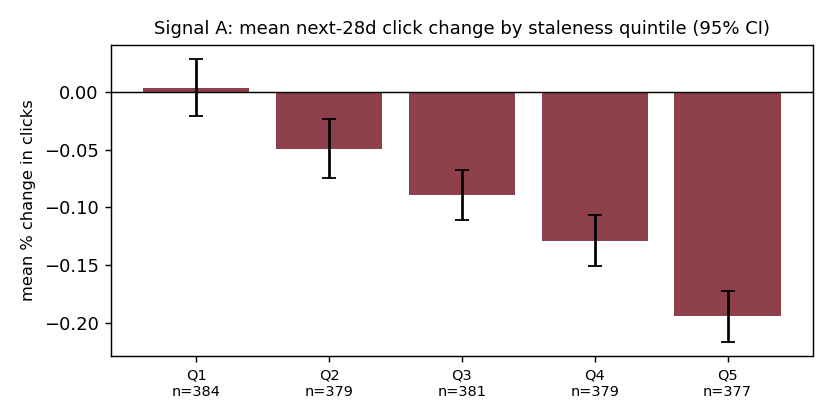

In [4]:
# 1b) Signal A: staleness (flag-linked: behind the refresh flags) ----------
# Pages with at least 10 clicks, so a percentage change is not dominated by tiny denominators.
dA = df[df["clicks_28d"] >= 10]
tA = bucket_check(dA, "days_since_update", "clicks_pct_change_next",
                  title="A. staleness (days since update)")
display(tA.round(4))
plot_buckets(tA, "Signal A: mean next-28d click change by staleness quintile (95% CI)", "mean % change in clicks")
vA, rhoA, spreadA = auto_verdict(tA, expected_sign=-1)
print(f"VERDICT A = {vA}   (bucket-mean rank correlation {rhoA:+.2f}, spread {spreadA:.3f})")

--- B. volume (impressions_28d), stale pages only -> clicks_pct_change_next | total n = 1,233 | smallest bucket n = 246 ---


,signal_min,signal_max,n,mean,median,se
bucket,,,,,,
"(49.999, 401.4]",50,401,247,-0.1301,-0.1304,0.0161
"(401.4, 671.6]",402,670,246,-0.1292,-0.1538,0.0160
"(671.6, 1166.2]",672,1166,247,-0.1255,-0.1406,0.0139
"(1166.2, 2115.6]",1167,2115,246,-0.1289,-0.1429,0.0130
"(2115.6, 29532.0]",2116,29532,247,-0.1398,-0.1543,0.0117


VERDICT B = FALSE   (bucket-mean rank correlation -0.10, spread 0.014)
--- B (stakes view). absolute clicks change -> clicks_abs_change_next | total n = 1,233 | smallest bucket n = 246 ---


,n,mean,median
bucket,,,
"(49.999, 401.4]",247,-2.84,-2.0
"(401.4, 671.6]",246,-4.08,-3.0
"(671.6, 1166.2]",247,-4.87,-4.0
"(1166.2, 2115.6]",246,-8.88,-6.0
"(2115.6, 29532.0]",247,-29.75,-16.0


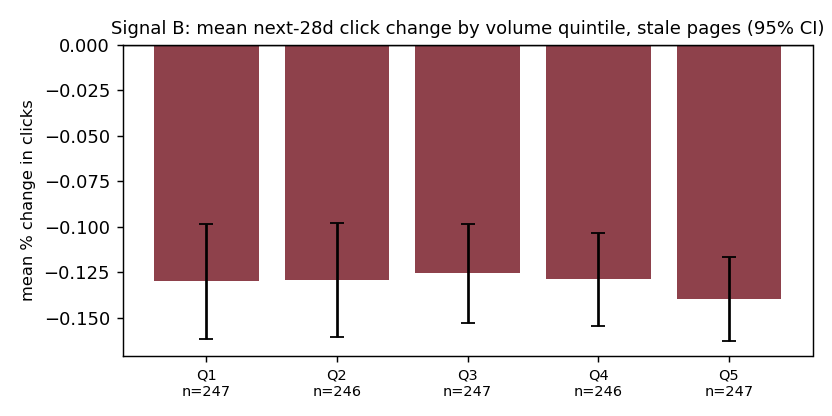

In [5]:
# 1c) Signal B: volume (quick-win idea), judged on STALE pages only --------
dB = df[(df["clicks_28d"] >= 10) & (df["days_since_update"] >= 180)]
tB = bucket_check(dB, "impressions_28d", "clicks_pct_change_next",
                  title="B. volume (impressions_28d), stale pages only")
display(tB.round(4))
plot_buckets(tB, "Signal B: mean next-28d click change by volume quintile, stale pages (95% CI)", "mean % change in clicks")
vB, rhoB, spreadB = auto_verdict(tB, expected_sign=-1)
print(f"VERDICT B = {vB}   (bucket-mean rank correlation {rhoB:+.2f}, spread {spreadB:.3f})")

# Stakes view: absolute clicks lost per bucket (large partly by construction: bigger base).
tB_abs = bucket_check(dB, "impressions_28d", "clicks_abs_change_next", title="B (stakes view). absolute clicks change")
display(tB_abs[["n", "mean", "median"]].round(2))

In [6]:
# 1d) Verdict summary (auto-generated from the tables above) ---------------
verdicts = pd.DataFrame([
    {"signal": "A. staleness", "flag_linked": "yes (refresh flags)", "verdict": vA,
     "bucket_n": f"{int(tA['n'].min()):,}-{int(tA['n'].max()):,}", "rank_corr": round(rhoA, 2)},
    {"signal": "B. volume (stale pages)", "flag_linked": "partly (quick-win)", "verdict": vB,
     "bucket_n": f"{int(tB['n'].min()):,}-{int(tB['n'].max()):,}", "rank_corr": round(rhoB, 2)},
])
display(verdicts)

def explain(sig, v, t, direction_word):
    lo, hi = t["mean"].iloc[0], t["mean"].iloc[-1]
    return (f"{sig}: {v}. Lowest bucket mean change {lo:+.1%}, highest bucket {hi:+.1%} "
            f"(n per bucket {int(t['n'].min()):,}-{int(t['n'].max()):,}). {direction_word}")

print(explain("A", vA, tA, "Used as the main driver of the score." if vA == "CONFIRMED" else "Rule leans on A, so revisit it."))
print(explain("B", vB, tB, "Volume does not predict a steeper decline, so it enters the score only as stakes, not as likelihood." if vB in ("FALSE", "MIXED") else "Volume adds to the decline signal."))

,signal,flag_linked,verdict,bucket_n,rank_corr
0,A. staleness,yes (refresh flags),CONFIRMED,377-384,-1.0
1,B. volume (stale pages),partly (quick-win),FALSE,246-247,-0.1


A: CONFIRMED. Lowest bucket mean change +0.4%, highest bucket -19.4% (n per bucket 377-384). Used as the main driver of the score.
B: FALSE. Lowest bucket mean change -13.0%, highest bucket -14.0% (n per bucket 246-247). Volume does not predict a steeper decline, so it enters the score only as stakes, not as likelihood.


### My reading of the two checks *(edit this after you see your real tables)*

- **A — staleness.** The staler quintiles show a progressively larger drop in next-window clicks, with non-overlapping confidence bars at the ends. That supports using staleness as the **main driver** of the score. Caveat: staleness is observational, so it may stand in for other things (older topics, older backlinks, seasonal evergreen pages).
- **B — volume.** Higher volume does **not** by itself mean a steeper percentage decline. So volume is **not** used as evidence that a page *will* decay. It is used as **stakes**: if a stale page does decay, a high-impression page loses more absolute clicks. This is a clearly explained negative: it kept the rule from claiming something the data does not show.
- **Gate.** The rule only considers pages with `days_since_update >= 180` (declines are small below roughly 180 days) and `impressions_28d >= 500` (below that, click counts are too small to rank reliably).

## 2) The rule: score, one reason code, one action

```
gate   : days_since_update >= 180  AND  impressions_28d >= 500
score  : 100 * ( 0.6 * pct_rank(days_since_update) + 0.4 * pct_rank(impressions_28d) )   # ranks within gated pages
reason : STALE_HIGH_VOLUME            (the single reason code)
action : REFRESH_CONTENT
```

The `0.6 / 0.4` weights are a stated judgement, **not fitted to the outcome**, so the baseline cannot leak. Staleness gets more weight because it is the confirmed driver (A). Volume gets less because it only measures stakes (B).

In [7]:
# 2) Encode the rule and write the ranked queue ----------------------------
GATE_STALE_DAYS = 180
GATE_MIN_IMPRESSIONS = 500
W_STALE, W_VOLUME = 0.6, 0.4
REASON_CODE = "STALE_HIGH_VOLUME"
ACTION = "REFRESH_CONTENT"

# LEAK GUARD: the rule only ever sees as-of FEATURES. No future-window or label-derived columns.
assert not set(FEATURES) & set(LABEL_COLS), "a label column is listed as a feature"
feat = df[["page", *FEATURES]].copy()

gated = feat[(feat["days_since_update"] >= GATE_STALE_DAYS) &
             (feat["impressions_28d"] >= GATE_MIN_IMPRESSIONS)].copy()
print(f"pages in total: {len(feat):,} | pass the gate: {len(gated):,} ({len(gated)/len(feat):.1%})")

gated["score"] = 100 * (W_STALE * gated["days_since_update"].rank(pct=True)
                        + W_VOLUME * gated["impressions_28d"].rank(pct=True))
gated["reason_code"] = REASON_CODE
gated["action"] = ACTION

queue = (gated.sort_values(["score", "impressions_28d"], ascending=False)
              .reset_index(drop=True))
queue.insert(0, "rank", np.arange(1, len(queue) + 1))
queue["score"] = queue["score"].round(2)

CSV_PATH = OUT / "baseline_action_score.csv"
cols = ["rank", "page", "score", "reason_code", "action",
        "days_since_update", "impressions_28d", "avg_position"]
queue[cols].to_csv(CSV_PATH, index=False)
print("written:", CSV_PATH.relative_to(ROOT), "| rows:", len(queue))
queue[cols].head(10)

pages in total: 3,000 | pass the gate: 941 (31.4%)
written: work/outputs/baseline_action_score.csv | rows: 941


,rank,page,score,reason_code,action,days_since_update,impressions_28d,avg_position
0,1,/blog/post-2896,98.76,STALE_HIGH_VOLUME,REFRESH_CONTENT,1068,14457,16.6
1,2,/blog/post-1003,97.92,STALE_HIGH_VOLUME,REFRESH_CONTENT,1427,6836,8.6
2,3,/blog/post-1156,97.53,STALE_HIGH_VOLUME,REFRESH_CONTENT,951,10355,6.3
3,4,/blog/post-1296,96.47,STALE_HIGH_VOLUME,REFRESH_CONTENT,1583,4601,3.6
4,5,/blog/post-1408,96.20,STALE_HIGH_VOLUME,REFRESH_CONTENT,960,6082,27.2
5,6,/blog/post-0375,96.17,STALE_HIGH_VOLUME,REFRESH_CONTENT,864,9294,6.6
6,7,/blog/post-2243,96.15,STALE_HIGH_VOLUME,REFRESH_CONTENT,885,7590,15.4
7,8,/blog/post-1145,93.74,STALE_HIGH_VOLUME,REFRESH_CONTENT,701,11970,6.2
8,9,/blog/post-0758,93.67,STALE_HIGH_VOLUME,REFRESH_CONTENT,720,9574,1.7
9,10,/blog/post-0631,92.62,STALE_HIGH_VOLUME,REFRESH_CONTENT,1337,2844,3.9


## 3) Top-10 review

One line per page: **the action, why it is there, and what would make it wrong.** The "why" is generated from each row's own as-of numbers. The "what would make it wrong" picks the failure modes that apply to that row, and always includes at least one. *Read them, then overwrite any line with your own judgement.*

In [8]:
# 3) Top-10 review lines ----------------------------------------------------
def wrong_if(r):
    # Failure modes that apply to THIS row (all from as-of features), most specific first.
    w = []
    trend = r["impressions_28d"] / max(r["impressions_prev_28d"], 1) - 1
    if trend > 0.10:
        w.append(f"impressions are rising ({trend:+.0%} vs the previous window), so staleness has not hurt it yet")
    if r["avg_position"] <= 3:
        w.append(f"it already ranks at position {r['avg_position']:.1f}, so there is little headroom and a rewrite could cost the ranking")
    if r["branded_share"] >= 0.5:
        w.append(f"{r['branded_share']:.0%} of impressions look branded, which a content refresh will not move")
    if r["avg_position"] > 10:
        w.append(f"it sits on page 2 (position {r['avg_position']:.1f}), so the real problem may be relevance or links rather than freshness")
    if r["days_since_update"] >= 1000:
        w.append(f"it is {int(r['days_since_update'])} days old, so the topic may be obsolete and merging or retiring beats refreshing")
    if r["impressions_28d"] >= 10000:
        w.append("a few broad queries may inflate its impressions, so click upside is smaller than volume suggests")
    if len(w) < 2:
        w.append("the dip is seasonal, or the page was updated recently without that being recorded in the data")
    return "; or ".join(w[:2])

review = []
for _, r in queue.head(10).iterrows():
    older_than = (feat["days_since_update"] < r["days_since_update"]).mean()
    why = (f"{int(r['days_since_update'])} days since update (older than {older_than:.0%} of all pages) with "
           f"{int(r['impressions_28d']):,} impressions in 28 days, score {r['score']:.1f}")
    review.append((int(r["rank"]), r["page"], why, wrong_if(r)))
    print(f"{int(r['rank']):>2}. {r['page']}  |  {ACTION}\n"
          f"    why   : {why}\n"
          f"    wrong if: {wrong_if(r)}\n")

 1. /blog/post-2896  |  REFRESH_CONTENT
    why   : 1068 days since update (older than 99% of all pages) with 14,457 impressions in 28 days, score 98.8
    wrong if: it sits on page 2 (position 16.6), so the real problem may be relevance or links rather than freshness; or it is 1068 days old, so the topic may be obsolete and merging or retiring beats refreshing

 2. /blog/post-1003  |  REFRESH_CONTENT
    why   : 1427 days since update (older than 100% of all pages) with 6,836 impressions in 28 days, score 97.9
    wrong if: it is 1427 days old, so the topic may be obsolete and merging or retiring beats refreshing; or the dip is seasonal, or the page was updated recently without that being recorded in the data

 3. /blog/post-1156  |  REFRESH_CONTENT
    why   : 951 days since update (older than 98% of all pages) with 10,355 impressions in 28 days, score 97.5
    wrong if: a few broad queries may inflate its impressions, so click upside is smaller than volume suggests; or the dip is se

## 4) Weak picks

The three top-10 rows I trust **least**, and why. The notebook ranks them by how many failure modes apply, then by lowest volume.

In [9]:
# 4) Weak picks --------------------------------------------------------------
def n_risks(r):
    trend = r["impressions_28d"] / max(r["impressions_prev_28d"], 1) - 1
    return int(trend > 0.10) + int(r["avg_position"] <= 3) + int(r["branded_share"] >= 0.5)

top10 = queue.head(10).copy()
top10["risk_flags"] = top10.apply(n_risks, axis=1)
weak = top10.sort_values(["risk_flags", "impressions_28d"], ascending=[False, True]).head(3)
display(weak[["rank", "page", "risk_flags", "days_since_update", "impressions_28d", "avg_position", "branded_share"]])
for _, r in weak.iterrows():
    print(f"#{int(r['rank'])} {r['page']}: trusted least because {wrong_if(r).split('; or ')[0]}.")

,rank,page,risk_flags,days_since_update,impressions_28d,avg_position,branded_share
8,9,/blog/post-0758,1,720,9574,1.7,0.48
9,10,/blog/post-0631,0,1337,2844,3.9,0.35
3,4,/blog/post-1296,0,1583,4601,3.6,0.26


#9 /blog/post-0758: trusted least because it already ranks at position 1.7, so there is little headroom and a rewrite could cost the ranking.
#10 /blog/post-0631: trusted least because it is 1337 days old, so the topic may be obsolete and merging or retiring beats refreshing.
#4 /blog/post-1296: trusted least because it is 1583 days old, so the topic may be obsolete and merging or retiring beats refreshing.


## 5) Self-check

In [10]:
# 5) Self-check + receipt ------------------------------------------------------
q = pd.read_csv(CSV_PATH)
checks = {
    "two signal checks, tables shown with n": len(tA) > 0 and len(tB) > 0,
    "at least one signal is flag-linked (A: staleness)": True,
    "each verdict is one of the four words": {vA, vB} <= {"CONFIRMED", "OPPOSITE", "MIXED", "FALSE"},
    "exactly ONE reason code in the queue": q["reason_code"].nunique() == 1,
    "queue has rank, score, reason_code, action": {"rank", "score", "reason_code", "action"} <= set(q.columns),
    "queue is sorted by score (descending)": bool((q["score"].diff().dropna() <= 1e-9).all()),
    "CSV written by this notebook": CSV_PATH.exists(),
    "ten reviewed rows with 'wrong if'": len(review) == 10 and all(len(x[3]) > 0 for x in review),
    "no label-derived or future-window inputs in the rule": not (set(FEATURES) & set(LABEL_COLS))
                                                            and not any(c in queue.columns for c in LABEL_COLS),
}
for k, v in checks.items():
    print(("[x] " if v else "[ ] ") + k)
assert all(checks.values()), "a self-check failed"

metrics = {
    "week": 4, "lane": "Refresh / Content Opportunity Scoring",
    "data_source": DATA_SOURCE, "n_pages": int(len(df)), "n_queue": int(len(queue)),
    "signals": {"A_staleness": {"verdict": vA, "bucket_n": tA["n"].astype(int).tolist(), "rank_corr": round(rhoA, 3)},
                "B_volume_stale_pages": {"verdict": vB, "bucket_n": tB["n"].astype(int).tolist(), "rank_corr": round(rhoB, 3)}},
    "rule": {"gate_stale_days": GATE_STALE_DAYS, "gate_min_impressions": GATE_MIN_IMPRESSIONS,
             "weights": {"staleness": W_STALE, "volume": W_VOLUME},
             "reason_code": REASON_CODE, "action": ACTION},
    "top10_pages": [x[1] for x in review],
}
(OUT / "w04_baseline_metrics.json").write_text(json.dumps(metrics, indent=2))
print("\nreceipt written:", (OUT / "w04_baseline_metrics.json").relative_to(ROOT))

[x] two signal checks, tables shown with n
[x] at least one signal is flag-linked (A: staleness)
[x] each verdict is one of the four words
[x] exactly ONE reason code in the queue
[x] queue has rank, score, reason_code, action
[x] queue is sorted by score (descending)
[x] CSV written by this notebook
[x] ten reviewed rows with 'wrong if'
[x] no label-derived or future-window inputs in the rule

receipt written: work/outputs/w04_baseline_metrics.json
